# Phát hiện SMS spam bằng SVD và PCA

Đồ án môn Toán cho Khoa học Máy tính. TF-IDF, SVD, PCA, Logistic Regression và các độ đo đều được tự cài bằng NumPy trong thư mục `src/`. Notebook gọi lại các hàm đó và giải thích từng bước theo thứ tự **công thức → code → kết quả → nhận xét**.

## 1. Bài toán

**Input:** một tin nhắn SMS tiếng Anh. **Output:** nhãn `ham` (tin thường) hoặc `spam` (tin rác), kèm xác suất P(spam).

Ta so sánh ba pipeline dùng chung một bộ phân loại:

```text
SMS → TF-IDF (1000 chiều) ─┬──────────────────→ Logistic Regression   (baseline)
                           ├─ SVD (k chiều) ──→ Logistic Regression
                           └─ PCA (k chiều) ──→ Logistic Regression
```

**Câu hỏi:** giảm từ 1000 chiều xuống k ∈ {10, 50, 100} chiều bằng SVD hoặc PCA thì khả năng phát hiện spam thay đổi thế nào?

Mọi bước học trong đồ án đều đi theo cùng một mạch: **mô hình → loss → tối ưu → score**.

| Bước | Mô hình | Loss (càng nhỏ càng tốt) | Tối ưu | Score (đánh giá) |
|---|---|---|---|---|
| SVD / PCA | $X \approx X_k = Z V_k^T$ | sai số tái tạo $\Vert X - X_k \Vert_F^2$ | orthogonal iteration | tỷ lệ năng lượng / phương sai giữ lại |
| Logistic Regression | $p = \sigma(Xw + b)$ | cross-entropy + L2 | gradient descent | accuracy, precision, recall, F1, **macro-F1** |

In [1]:
from pathlib import Path
import os
import sys

# Tìm thư mục project để chạy được cả khi mở notebook từ thư mục con.
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import json

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src import plots
from src.data import DEFAULT_DATA, download_data
from src.decomposition import PCA, TruncatedSVD, top_eigenvectors
from src.logistic import LogisticRegressionGD, gradient_check, sigmoid
from src.metrics import classification_scores, confusion_matrix
from src.pipeline import K_VALUES, METHODS, load_pipeline, to_binary
from src.predict import predict_message
from src.tfidf import TfidfVectorizer
from src.train import (DEMO_MESSAGES, choose_k, prepare_data, refit_and_test,
                       run_validation_sweep, save_json, save_run_config)

OUTPUT_ROOT = Path("outputs")
RESULTS, FIGURES = OUTPUT_ROOT / "results", OUTPUT_ROOT / "figures"
for folder in (RESULTS, FIGURES, OUTPUT_ROOT / "models"):
    folder.mkdir(parents=True, exist_ok=True)


def show_table(frame, digits=4):
    """Hiển thị DataFrame thành bảng Markdown, số thực làm tròn."""
    def cell(x):
        if pd.isna(x):
            return "—"
        if isinstance(x, (float, np.floating)):
            return f"{x:.{digits}f}"
        return str(x).replace("|", "\\|")
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * frame.shape[1]]
    lines += ["| " + " | ".join(cell(x) for x in row) + " |" for row in frame.itertuples(index=False)]
    display(Markdown("\n".join(lines)))


def show_figure(name):
    display(Image(filename=FIGURES / name))


print(f"NumPy {np.__version__}, pandas {pd.__version__}")

NumPy 2.5.4, pandas 3.0.6


## 2. Dữ liệu

Bộ [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) gồm 5.574 tin nhắn tiếng Anh có nhãn. Ta chuyển chữ về chữ thường, gộp khoảng trắng và bỏ các tin trùng nội dung. Bước loại trùng làm **trước** khi chia tập để một tin không xuất hiện ở hai tập.

`stratified_split(df, (0.7, 0.15, 0.15), seed=42)` xáo riêng từng lớp bằng `np.random.default_rng(42)` rồi cắt theo tỷ lệ. Với lớp $c$ có $n_c$ tin:

$$
n_c^{\mathrm{train}} = \mathrm{round}(0{,}7 n_c), \qquad n_c^{\mathrm{val}} = \mathrm{round}(0{,}15 n_c), \qquad n_c^{\mathrm{test}} = n_c - n_c^{\mathrm{train}} - n_c^{\mathrm{val}},
$$

nên ba tập có cùng tỷ lệ spam.

| Tập | Dùng để |
|---|---|
| Train (70%) | học vocabulary, idf, $V_k$, $\mu$, $w$, $b$ |
| Validation (15%) | chọn k |
| Test (15%) | đánh giá **một lần** ở cuối |

Đọc 5574 dòng, bỏ 415 tin trùng → còn 5159 tin.


| Tập | Số tin | Ham | Spam | Tỷ lệ spam |
|---|---|---|---|---|
| train | 3611 | 3162 | 449 | 0.1243 |
| validation | 774 | 678 | 96 | 0.1240 |
| test | 774 | 677 | 97 | 0.1253 |

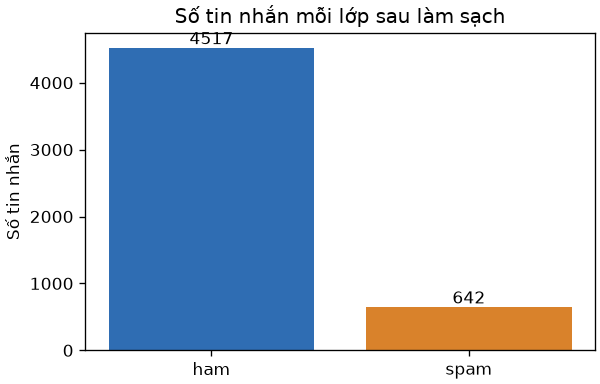

In [2]:
download_data(DEFAULT_DATA)                   # Chỉ tải khi máy chưa có file.
splits = prepare_data(DEFAULT_DATA, RESULTS)  # Làm sạch rồi stratified_split(..., (0.7, 0.15, 0.15), seed=42)
summary = json.loads((RESULTS / "data_summary.json").read_text(encoding="utf-8"))
print(f"Đọc {summary['raw_rows']} dòng, bỏ {summary['duplicates_removed']} tin trùng "
      f"→ còn {summary['clean_rows']} tin.")
show_table(pd.DataFrame([
    {"Tập": name, "Số tin": c["rows"], "Ham": c["ham"], "Spam": c["spam"],
     "Tỷ lệ spam": c["spam"] / c["rows"]}
    for name, c in summary["splits"].items()
]))
plots.plot_class_distribution(summary["class_counts"], FIGURES / "class_distribution.png")
show_figure("class_distribution.png")

**Nhận xét.** Spam chỉ chiếm 12,4–12,5% ở cả ba tập, nên một mô hình luôn đoán "ham" đã đạt accuracy khoảng 87,5% mà không bắt được tin spam nào. Vì vậy ta chọn k bằng **macro-F1** và theo dõi thêm **recall của lớp spam**.

## 3. TF-IDF: biến văn bản thành ma trận

Mỗi tin nhắn trở thành một hàng của ma trận $X \in \mathbb{R}^{N \times D}$, mỗi cột ứng với một từ. Ta tách từ bằng regex `\b\w\w+\b` (chuỗi chữ/số dài từ 2 ký tự), giữ các từ có trong ít nhất 2 tin train (`min_df=2`), rồi lấy 1000 từ xuất hiện nhiều nhất. Với từ $t$ xuất hiện $f$ lần trong một tin:

$$
\mathrm{tf} = 1 + \log f, \qquad
\mathrm{idf}(t) = \log\frac{1 + N}{1 + \mathrm{df}(t)} + 1, \qquad
x_t = \mathrm{tf} \cdot \mathrm{idf}(t).
$$

Trong đó $\mathrm{df}(t)$ là số tin train chứa $t$. Sau đó mỗi hàng được chia cho chuẩn L2 của nó. `fit` chỉ học vocabulary và idf trên train, còn validation/test chỉ đi qua `transform`.

In [3]:
train_texts = splits["train"]["text"].tolist()
y_train = to_binary(splits["train"]["label"])           # spam = 1, ham = 0
vectorizer = TfidfVectorizer(max_features=1000, min_df=2).fit(train_texts)
X_train = vectorizer.transform(train_texts)
N, D = X_train.shape
print(f"X_train: {N} tin × {D} từ; phần tử khác 0: {np.mean(X_train != 0):.2%}")

i = int(np.argmax(y_train))                             # tin spam đầu tiên trong train
words = vectorizer.feature_names()
nonzero = np.flatnonzero(X_train[i])
print("Tin nhắn:", train_texts[i])
show_table(pd.DataFrame({"Từ": [words[j] for j in nonzero], "TF-IDF": X_train[i, nonzero]}))
print(f"Chuẩn L2 của hàng này: {np.linalg.norm(X_train[i]):.4f}")

X_train: 3611 tin × 1000 từ; phần tử khác 0: 1.04%
Tin nhắn: get 3 lions england tone, reply lionm 4 mono or lionp 4 poly. 4 more go 2 www.ringtones.co.uk, the original n best. tones 3gbp network operator rates apply


| Từ | TF-IDF |
|---|---|
| apply | 0.2768 |
| best | 0.2485 |
| co | 0.2566 |
| get | 0.1614 |
| go | 0.1758 |
| more | 0.2244 |
| network | 0.2768 |
| operator | 0.3011 |
| or | 0.1618 |
| poly | 0.2904 |
| rates | 0.3053 |
| reply | 0.2069 |
| the | 0.1172 |
| tone | 0.2629 |
| tones | 0.2845 |
| uk | 0.2417 |
| www | 0.2289 |

Chuẩn L2 của hàng này: 1.0000


**Nhận xét.** Trung bình mỗi tin chỉ dùng khoảng 10 trong 1000 từ (1,04% phần tử khác 0), nên X rất thưa. Các từ ít gặp như *rates*, *operator* có trọng số cao hơn từ phổ biến như *the*; đó là tác dụng của idf.

## 4. SVD: giảm chiều bằng xấp xỉ hạng thấp

**Mô hình.** $X = U \Sigma V^T$. Vì $X^T X = V \Sigma^2 V^T$, các cột $v_j$ của $V$ là vector riêng của $X^T X$ và $\sigma_j = \sqrt{\lambda_j}$. Giữ $k$ hướng đầu:

$$
Z = X V_k \in \mathbb{R}^{N \times k}, \qquad X_k = Z V_k^T.
$$

Mỗi tin nhắn chỉ còn $k$ tọa độ. Mỗi tọa độ là tổ hợp tuyến tính của cả 1000 từ, chứ không phải $k$ từ được chọn ra.

**Tối ưu bằng orthogonal iteration.** Bắt đầu từ ma trận ngẫu nhiên $Q$ ($D \times k$), lặp $Q \leftarrow \mathrm{QR}(X^T X Q)$. Phép nhân khuếch đại các hướng có $\lambda$ lớn, còn QR giữ các cột trực chuẩn, nên $Q$ tiến dần về $V_k$. Vòng lặp dừng khi mọi $\lambda_j = q_j^T X^T X q_j$ thay đổi ít hơn $10^{-8}\lambda_1$.

**Loss và score** (score là tỷ lệ năng lượng giữ lại):

$$
\mathrm{loss} = \Vert X - X_k \Vert_F^2 = \sum_{j \gt k} \sigma_j^2, \qquad
\mathrm{score} = \frac{\sum_{j \le k} \sigma_j^2}{\Vert X \Vert_F^2}.
$$

Định lý Eckart–Young cho biết không có ma trận hạng $k$ nào có loss nhỏ hơn $X_k$. Ô dưới kiểm tra hai điều: các cột của $V_k$ đúng là vector riêng (phần dư $X^TXv_j - \lambda_j v_j$ gần 0), và loss của SVD nhỏ hơn hẳn loss khi chiếu lên 100 hướng ngẫu nhiên.

In [4]:
svd = TruncatedSVD(k=100).fit(X_train)
print(f"Orthogonal iteration hội tụ sau {svd.n_iter_} vòng.")
print("σ_1..σ_5 =", svd.singular_values_[:5].round(3))

# 1) v_j là vector riêng của XᵀX: phần dư rất nhỏ so với λ_1.
G, V, lam = X_train.T @ X_train, svd.components_.T, svd.singular_values_ ** 2
print(f"max_j ‖XᵀX·v_j − λ_j·v_j‖ / λ_1 = {np.max(np.linalg.norm(G @ V - V * lam, axis=0)) / lam[0]:.1e}")

# 2) Eckart–Young: so với chiếu lên 100 hướng ngẫu nhiên (trực chuẩn).
Q, _ = np.linalg.qr(np.random.default_rng(0).standard_normal((D, 100)))
X_random = X_train @ Q @ Q.T
print(f"loss SVD = {svd.loss():.1f};  loss với 100 hướng ngẫu nhiên = {np.sum((X_train - X_random) ** 2):.1f}")

energy = svd.singular_values_ ** 2   # σ_j² giảm dần; với k nhỏ hơn chỉ cần lấy k số đầu
show_table(pd.DataFrame([
    {"k": k, "loss = ‖X − X_k‖²": svd.total_energy_ - energy[:k].sum(),
     "score = năng lượng giữ lại": energy[:k].sum() / svd.total_energy_}
    for k in K_VALUES
]))

Orthogonal iteration hội tụ sau 2414 vòng.
σ_1..σ_5 = [11.217  6.078  5.675  5.558  5.421]
max_j ‖XᵀX·v_j − λ_j·v_j‖ / λ_1 = 2.0e-05
loss SVD = 2043.3;  loss với 100 hướng ngẫu nhiên = 3232.5


| k | loss = ‖X − X_k‖² | score = năng lượng giữ lại |
|---|---|---|
| 10 | 3212.0912 | 0.1055 |
| 50 | 2553.5868 | 0.2889 |
| 100 | 2043.2843 | 0.4310 |

**Nhận xét.** Phần dư chỉ cỡ $10^{-5}$, và loss của SVD (2043) nhỏ hơn nhiều so với khi dùng 100 hướng ngẫu nhiên (3232), đúng như Eckart–Young. Dù vậy, 100 chiều (10% số cột) chỉ giữ được 43,1% năng lượng, vì sau $\sigma_1 = 11{,}2$ các $\sigma_j$ giảm rất chậm (từ 6,1 xuống 2,9 ở $j = 100$).

## 5. PCA: SVD trên dữ liệu đã trừ mean

**Mô hình.** Trừ mean $\mu$ (học trên train): $X_c = X - \mu$. Ma trận hiệp phương sai là

$$
C = \frac{X_c^T X_c}{N - 1} = V \frac{\Sigma^2}{N - 1} V^T,
$$

nên các thành phần chính chính là $V_k$ trong SVD của $X_c$, và phương sai của thành phần $j$ bằng $\sigma_j^2 / (N - 1)$. Vì vậy PCA dùng lại đúng orthogonal iteration ở mục 4 với $X_c$ thay cho $X$, rồi lấy $Z = (X - \mu) V_k$. Validation và test cũng trừ $\mu$ của train.

**Loss và score.** $\mathrm{loss} = \Vert X_c - X_{c,k} \Vert_F^2 = \sum_{j \gt k} \sigma_j^2$ và $\mathrm{score} = \sum_{j \le k} \sigma_j^2 / \sum_j \sigma_j^2$, tức tỷ lệ phương sai giữ lại.

Orthogonal iteration hội tụ sau 2405 vòng.
Phương sai 5 thành phần đầu σ_j²/(N−1) = [0.0118  0.00903 0.00885 0.00818 0.00763]
max_j ‖X_cᵀX_c·v_j − λ_j·v_j‖ / λ_1 = 3.5e-05


| k | loss = ‖X_c − X_c,k‖² | score = phương sai giữ lại |
|---|---|---|
| 10 | 3202.1495 | 0.0819 |
| 50 | 2549.0764 | 0.2692 |
| 100 | 2040.0539 | 0.4151 |

cos(góc giữa v_1 của SVD và μ) = 0.989


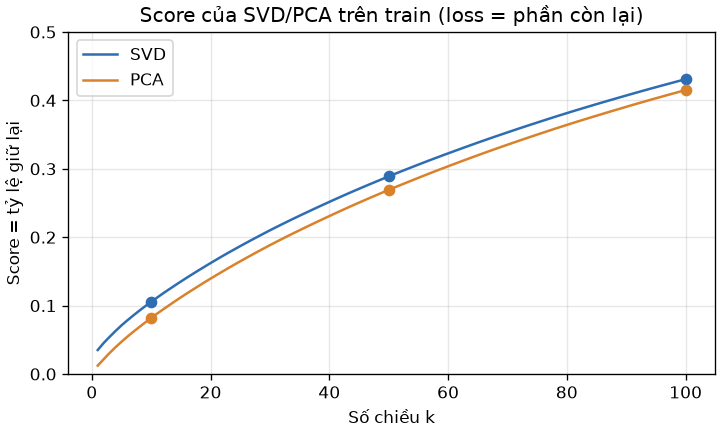

In [5]:
pca = PCA(k=100).fit(X_train)
print(f"Orthogonal iteration hội tụ sau {pca.n_iter_} vòng.")
print("Phương sai 5 thành phần đầu σ_j²/(N−1) =", pca.explained_variance_[:5].round(5))

X_c = X_train - pca.mean_
G_c, V_c, lam_c = X_c.T @ X_c, pca.components_.T, pca.singular_values_ ** 2
print(f"max_j ‖X_cᵀX_c·v_j − λ_j·v_j‖ / λ_1 = {np.max(np.linalg.norm(G_c @ V_c - V_c * lam_c, axis=0)) / lam_c[0]:.1e}")

variance = pca.singular_values_ ** 2
show_table(pd.DataFrame([
    {"k": k, "loss = ‖X_c − X_c,k‖²": pca.total_energy_ - variance[:k].sum(),
     "score = phương sai giữ lại": variance[:k].sum() / pca.total_energy_}
    for k in K_VALUES
]))
cos = abs(svd.components_[0] @ pca.mean_) / np.linalg.norm(pca.mean_)
print(f"cos(góc giữa v_1 của SVD và μ) = {cos:.3f}")

spectrum = {name: {"singular_values": m.singular_values_.tolist(), "total_energy": m.total_energy_}
            for name, m in (("svd", svd), ("pca", pca))}
plots.plot_retention(spectrum, FIGURES / "retention.png")
show_figure("retention.png")

**Nhận xét.** Hướng đầu của SVD gần trùng với hướng của vector mean ($\cos = 0{,}989$): SVD dùng hướng mạnh nhất để biểu diễn "tin nhắn trung bình", còn PCA đã trừ $\mu$ từ trước. Ở k = 100, PCA giữ 41,5% phương sai; score của SVD và PCA đo trên hai ma trận khác nhau ($X$ và $X_c$) nên không so trực tiếp.

## 6. Logistic Regression: từ loss function đến score function

Đây là phần trọng tâm. Logistic Regression đi qua 5 bước: mô hình → loss → gradient → tối ưu → dự đoán và score. Mỗi bước là một hoặc hai hàm trong `src/logistic.py`, và docstring của hàm ghi đúng công thức của bước đó.

### 6.1. Mô hình

$$
z = Xw + b, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}} = P(\mathrm{spam} \mid x).
$$

Hàm sigmoid ép điểm $z$ về khoảng $(0, 1)$. Hàm trong code: `sigmoid`, `predict_proba`.

In [6]:
z = np.array([-6.0, -2.0, 0.0, 2.0, 6.0])
print("z    =", z)
print("σ(z) =", sigmoid(z).round(4))

z    = [-6. -2.  0.  2.  6.]
σ(z) = [0.0025 0.1192 0.5    0.8808 0.9975]


**Nhận xét.** $z \gt 0$ thì $p \gt 0{,}5$ (dự đoán spam); $|z|$ càng lớn thì mô hình càng chắc chắn.

### 6.2. Loss function: Binary Cross-Entropy + L2

$$
J(w, b) = -\frac{1}{N} \sum_{i=1}^{N} \Big[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \Big] + \frac{\lambda}{2N} \Vert w \Vert^2 .
$$

- Một tin spam ($y = 1$) mà mô hình cho $p$ nhỏ sẽ có $-\log p$ lớn, tức bị phạt nặng khi đoán sai mà lại tự tin.
- Số hạng L2 giữ $w$ nhỏ để tránh overfit. Ta dùng $\lambda = 1$, tương đương `C = 1` của bản trước; $b$ không bị phạt.
- $p$ được clip vào $[10^{-12}, 1 - 10^{-12}]$ để tránh $\log 0$. Hàm trong code: `loss`.

In [7]:
clf = LogisticRegressionGD(lam=1.0)
clf.w, clf.b = np.zeros(D), 0.0
print(f"J(w = 0, b = 0) = {clf.loss(X_train, y_train):.4f}   (log 2 = {np.log(2):.4f}, vì lúc này p = 0.5 với mọi tin)")

J(w = 0, b = 0) = 0.6931   (log 2 = 0.6931, vì lúc này p = 0.5 với mọi tin)

### 6.3. Gradient

Dùng $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, đạo hàm của $J$ rút gọn thành

$$
\frac{\partial J}{\partial w} = \frac{1}{N} X^T (p - y) + \frac{\lambda}{N} w, \qquad
\frac{\partial J}{\partial b} = \frac{1}{N} \sum_{i} (p_i - y_i).
$$

**Gradient check:** so gradient tính theo công thức với sai phân trung tâm $\frac{J(\theta + \varepsilon) - J(\theta - \varepsilon)}{2\varepsilon}$ ($\varepsilon = 10^{-6}$). Phép so được làm trên 50 tin nhắn, tại một điểm $(w, b)$ ngẫu nhiên. Hàm trong code: `gradient`, `gradient_check`.

In [8]:
error = gradient_check(X_train[:50], y_train[:50], lam=1.0)
print(f"Sai số lớn nhất giữa gradient công thức và gradient số ({D + 1} tham số): {error:.2e}")
assert error < 1e-6

Sai số lớn nhất giữa gradient công thức và gradient số (1001 tham số): 2.14e-09


**Nhận xét.** Sai số chỉ khoảng $2 \cdot 10^{-9}$, nhỏ hơn nhiều so với ngưỡng $10^{-6}$, nên công thức gradient ở trên là đúng.

### 6.4. Tối ưu bằng gradient descent

$$
w \leftarrow w - \eta \frac{\partial J}{\partial w}, \qquad b \leftarrow b - \eta \frac{\partial J}{\partial b}.
$$

Bắt đầu từ $w = 0$, $b = 0$ và lưu $J$ sau mỗi epoch. Vòng lặp dừng khi đủ 20.000 epoch hoặc khi $\vert J^{(t)} - J^{(t-1)} \vert \lt 10^{-10}$. Hàm trong code: `fit`.

**Chọn learning rate η.** Gọi $L$ là hằng số Lipschitz của gradient, tức gradient đổi nhanh nhất đến mức nào. Vì $\sigma' \le 1/4$, ta có $L \le \frac{1}{4} \lambda_{\max}\big([X\ \mathbf{1}]^T [X\ \mathbf{1}]\big)/N + \lambda/N$, và với $\eta \lt 2/L$ thì $J$ chắc chắn giảm sau mỗi bước.

Trị riêng lớn nhất không vượt quá tổng đường chéo: $\lambda_{\max} \le \sum_i (\Vert x_i \Vert^2 + 1) \le 2N$. Lý do là mỗi hàng TF-IDF có chuẩn 1, hoặc bằng 0 nếu tin không chứa từ nào trong vocabulary. Với đặc trưng $Z$ của SVD/PCA cũng có $\Vert Z \Vert_F^2 \le N$. Suy ra $L \le 0{,}5 + \lambda/N$ cho cả ba pipeline, và ta chọn **η = 2**.

Ô dưới tính $L$ thật bằng `top_eigenvectors` của mục 4 với $k = 1$ (lúc này orthogonal iteration chính là power iteration), rồi thử ba giá trị η, mỗi giá trị chạy 2000 epoch.

L = 0.2575  →  J chắc chắn giảm khi η < 2/L = 7.77


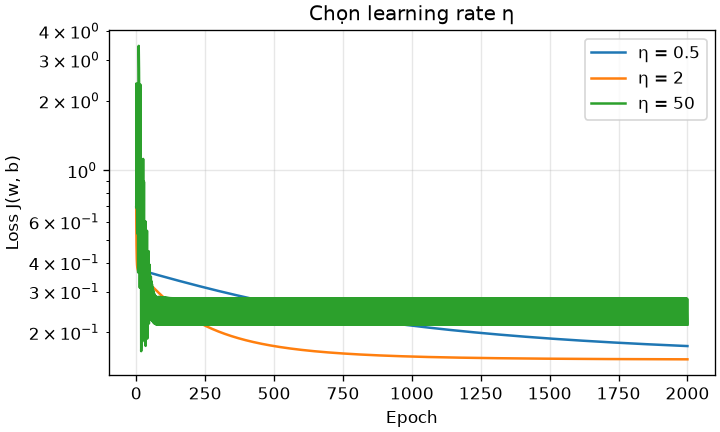

In [9]:
M = np.hstack([X_train, np.ones((N, 1))])                    # thêm cột 1 ứng với b
L = 0.25 * top_eigenvectors(M.T @ M, 1)[0][0] / N + 1.0 / N
print(f"L = {L:.4f}  →  J chắc chắn giảm khi η < 2/L = {2 / L:.2f}")

histories = {lr: LogisticRegressionGD(lr=lr, epochs=2000, tol=0).fit(X_train, y_train).loss_history_
             for lr in (0.5, 2, 50)}
plots.plot_learning_rates(histories, FIGURES / "learning_rate.png")
show_figure("learning_rate.png")

**Nhận xét.** $L = 0{,}2575$, nên ngưỡng an toàn là $\eta \lt 7{,}77$. Với η = 50, loss dao động; với η = 0,5, loss giảm quá chậm; còn η = 2 vừa an toàn vừa giảm nhanh.

In [10]:
clf = LogisticRegressionGD(lam=1.0, lr=2.0, epochs=20000, tol=1e-10).fit(X_train, y_train)
history = np.array(clf.loss_history_)
print(f"Dừng sau {clf.n_epochs_} epoch: J giảm từ {history[0]:.4f} xuống {history[-1]:.6f}")
print("J giảm sau mọi epoch:", bool(np.all(np.diff(history) <= 0)))
grad_w, grad_b = clf.gradient(X_train, y_train)
print(f"Tại điểm dừng: ‖∂J/∂w‖ = {np.linalg.norm(grad_w):.1e}, |∂J/∂b| = {abs(grad_b):.1e}")

Dừng sau 8298 epoch: J giảm từ 0.6931 xuống 0.152365
J giảm sau mọi epoch: True
Tại điểm dừng: ‖∂J/∂w‖ = 7.1e-06, |∂J/∂b| = 1.5e-07


**Nhận xét.** GD dừng sau 8298 epoch vì $|\Delta J| \lt 10^{-10}$ (chưa chạm giới hạn 20.000), và $J$ giảm sau mọi epoch, từ 0,6931 xuống 0,1524. Gradient tại điểm dừng gần bằng 0, nên GD đã đến rất gần cực tiểu; vì $J$ lồi, đó là cực tiểu toàn cục.

### 6.5. Dự đoán và score function

Dự đoán $\hat y = 1$ (spam) nếu $p \ge 0{,}5$, ngược lại $\hat y = 0$ (ham). Score function đếm bốn loại kết quả:

| | Dự đoán ham | Dự đoán spam |
|---|---|---|
| **Thật là ham** | TN | FP (báo nhầm) |
| **Thật là spam** | FN (bỏ sót) | TP |

$$
\mathrm{accuracy} = \frac{TP + TN}{N}, \quad
P = \frac{TP}{TP + FP}, \quad
R = \frac{TP}{TP + FN}, \quad
F_1 = \frac{2PR}{P + R}, \quad
F_1^{\mathrm{macro}} = \frac{F_1^{\mathrm{spam}} + F_1^{\mathrm{ham}}}{2}.
$$

$F_1^{\mathrm{ham}}$ tính giống hệt, chỉ đổi vai để coi ham là lớp dương. Hàm trong code: `predict`, `score`, cùng `confusion_matrix` và `classification_scores` trong `src/metrics.py`.

**Ví dụ tính tay.** Giả sử mô hình dự đoán 6 tin như bảng dưới. Khi đó TP = 1, FN = 1, FP = 1, TN = 3, và

- accuracy = 4/6 ≈ 0,667;
- spam: P = 1/(1+1) = 0,5, R = 1/(1+1) = 0,5, nên $F_1^{\mathrm{spam}}$ = 0,5;
- ham: P = 3/(3+1) = 0,75, R = 3/(3+1) = 0,75, nên $F_1^{\mathrm{ham}}$ = 0,75;
- macro-F1 = (0,5 + 0,75)/2 = 0,625.

In [11]:
example = pd.DataFrame({
    "Tin nhắn": ["WIN a free prize, call now", "Claim your cash reward today",
                 "Free lunch at the office?", "See you at 7", "Ok thanks", "Meeting moved to Monday"],
    "Thật": ["spam", "spam", "ham", "ham", "ham", "ham"],
    "Dự đoán": ["spam", "ham", "spam", "ham", "ham", "ham"],
})
show_table(example)
y_true, y_pred = to_binary(example["Thật"]), to_binary(example["Dự đoán"])
(tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
print(f"TP = {tp}, FN = {fn}, FP = {fp}, TN = {tn}")
show_table(pd.DataFrame([classification_scores(y_true, y_pred)]))

| Tin nhắn | Thật | Dự đoán |
|---|---|---|
| WIN a free prize, call now | spam | spam |
| Claim your cash reward today | spam | ham |
| Free lunch at the office? | ham | spam |
| See you at 7 | ham | ham |
| Ok thanks | ham | ham |
| Meeting moved to Monday | ham | ham |

TP = 1, FN = 1, FP = 1, TN = 3


| accuracy | spam_precision | spam_recall | spam_f1 | ham_f1 | macro_f1 |
|---|---|---|---|---|---|
| 0.6667 | 0.5000 | 0.5000 | 0.5000 | 0.7500 | 0.6250 |

Code cho đúng các số đã tính tay. Áp dụng cùng score function cho baseline vừa học (fit trên train, đánh giá trên validation):

In [12]:
X_val = vectorizer.transform(splits["validation"]["text"].tolist())
y_val = to_binary(splits["validation"]["label"])
show_table(pd.DataFrame([clf.score(X_val, y_val)]))

| accuracy | spam_precision | spam_recall | spam_f1 | ham_f1 | macro_f1 |
|---|---|---|---|---|---|
| 0.9690 | 0.9737 | 0.7708 | 0.8605 | 0.9826 | 0.9215 |

**Nhận xét.** Trên validation, baseline có precision spam 97,4% nhưng recall chỉ 77,1%: khi đã báo spam thì gần như luôn đúng, nhưng cứ 100 tin spam thì bỏ sót khoảng 23 tin. Macro-F1 = 0,9215.

## 7. Chọn k trên validation

$$
k^* = \arg\max_{k \in \lbrace 10, 50, 100 \rbrace} F_1^{\mathrm{macro}}(k).
$$

Ở đây $F_1^{\mathrm{macro}}(k)$ là macro-F1 trên validation; nếu bằng nhau thì lấy $k$ nhỏ hơn. Với từng pipeline và từng $k$, ta fit trên train rồi gọi `score` trên validation. Hàm `run_validation_sweep` lặp lại đúng các bước của mục 3–6 cho mỗi cấu hình. **Test chưa được dùng ở bước này.**

Validation baseline k=None: macro-F1=0.9215, GD 8298 epoch


Validation svd      k=10: macro-F1=0.8349, GD 5196 epoch


Validation svd      k=50: macro-F1=0.8759, GD 6013 epoch


Validation svd      k=100: macro-F1=0.9065, GD 6388 epoch


Validation pca      k=10: macro-F1=0.8441, GD 5022 epoch


Validation pca      k=50: macro-F1=0.8759, GD 6057 epoch


Validation pca      k=100: macro-F1=0.9027, GD 6388 epoch


| method | k | accuracy | spam_precision | spam_recall | macro_f1 | retained_ratio | decomposition_iterations | gd_epochs |
|---|---|---|---|---|---|---|---|---|
| baseline | — | 0.9690 | 0.9737 | 0.7708 | 0.9215 | — | — | 8298 |
| svd | 10 | 0.9419 | 0.9636 | 0.5521 | 0.8349 | 0.1055 | 263 | 5196 |
| svd | 50 | 0.9535 | 0.9545 | 0.6562 | 0.8759 | 0.2889 | 1352 | 6013 |
| svd | 100 | 0.9638 | 0.9722 | 0.7292 | 0.9065 | 0.4310 | 2414 | 6388 |
| pca | 10 | 0.9444 | 0.9649 | 0.5729 | 0.8441 | 0.0819 | 341 | 5022 |
| pca | 50 | 0.9535 | 0.9545 | 0.6562 | 0.8759 | 0.2692 | 893 | 6057 |
| pca | 100 | 0.9625 | 0.9718 | 0.7188 | 0.9027 | 0.4151 | 2405 | 6388 |

k chọn theo validation: {'svd': 100, 'pca': 100}


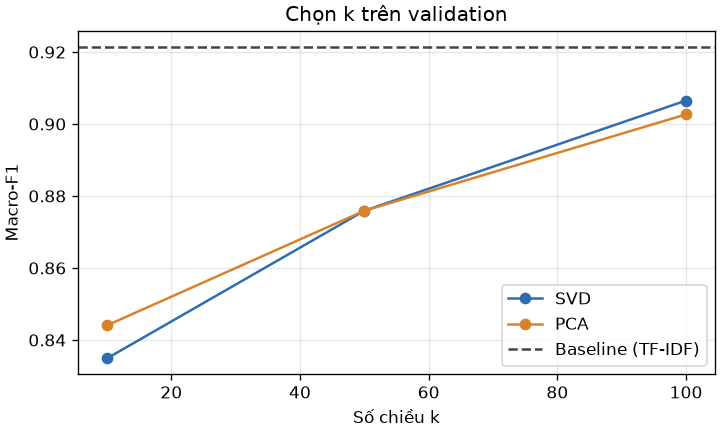

In [13]:
validation, spectrum = run_validation_sweep(splits)
validation.to_csv(RESULTS / "validation_metrics.csv", index=False)
save_json(RESULTS / "spectrum.json", spectrum)
selected = {method: choose_k(validation, method) for method in ("svd", "pca")}
save_json(RESULTS / "selected_k.json", selected)
show_table(validation[["method", "k", "accuracy", "spam_precision", "spam_recall", "macro_f1",
                       "retained_ratio", "decomposition_iterations", "gd_epochs"]])
print("k chọn theo validation:", selected)
plots.plot_validation_f1(validation, FIGURES / "validation_f1.png")
show_figure("validation_f1.png")

**Nhận xét.** Macro-F1 tăng theo k và cao nhất ở k = 100 cho cả SVD (0,9065) và PCA (0,9027), nhưng vẫn thấp hơn baseline (0,9215). Ở k = 10, recall spam chỉ còn 55–57%: giữ quá ít chiều làm mất nhiều tín hiệu nhận ra spam.

## 8. Kết quả trên test

$$
\mathrm{model} = \mathrm{fit}(\mathrm{train} \cup \mathrm{validation}, k^*), \qquad \mathrm{score}(\mathrm{model}, \mathrm{test}).
$$

Điểm test chỉ được tính đúng một lần. Mô hình được lưu bằng `np.savez` (các mảng số) cùng một file JSON (vocabulary) trong `outputs/models/`.

TEST baseline: accuracy=0.9780, macro-F1=0.9468


TEST svd     : accuracy=0.9703, macro-F1=0.9259


TEST pca     : accuracy=0.9703, macro-F1=0.9259


| method | k | accuracy | spam_precision | spam_recall | spam_f1 | macro_f1 |
|---|---|---|---|---|---|---|
| baseline | — | 0.9780 | 0.9762 | 0.8454 | 0.9061 | 0.9468 |
| svd | 100 | 0.9703 | 0.9744 | 0.7835 | 0.8686 | 0.9259 |
| pca | 100 | 0.9703 | 0.9744 | 0.7835 | 0.8686 | 0.9259 |

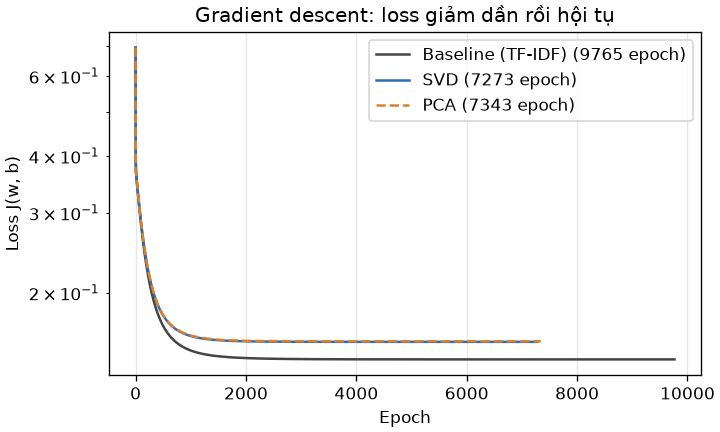

baseline: 9765 epoch, J cuối = 0.1427, J giảm sau mọi epoch: True
svd     : 7273 epoch, J cuối = 0.1559, J giảm sau mọi epoch: True
pca     : 7343 epoch, J cuối = 0.1564, J giảm sau mọi epoch: True


In [14]:
test = refit_and_test(splits, selected, OUTPUT_ROOT)
save_run_config(RESULTS)
show_table(test[["method", "k", "accuracy", "spam_precision", "spam_recall", "spam_f1", "macro_f1"]])

loss_history = json.loads((RESULTS / "loss_history.json").read_text(encoding="utf-8"))
plots.plot_loss_curves(loss_history, FIGURES / "loss_curve.png")
show_figure("loss_curve.png")
for method, h in loss_history.items():
    print(f"{method:8s}: {len(h) - 1} epoch, J cuối = {h[-1]:.4f}, "
          f"J giảm sau mọi epoch: {bool(np.all(np.diff(h) <= 0))}")

**Nhận xét.** Trên test, baseline đạt macro-F1 0,9468, còn SVD và PCA với k = 100 cùng đạt 0,9259, thấp hơn 0,021. Loss của cả ba pipeline giảm sau mọi epoch, và GD dừng trước giới hạn 20.000 epoch.

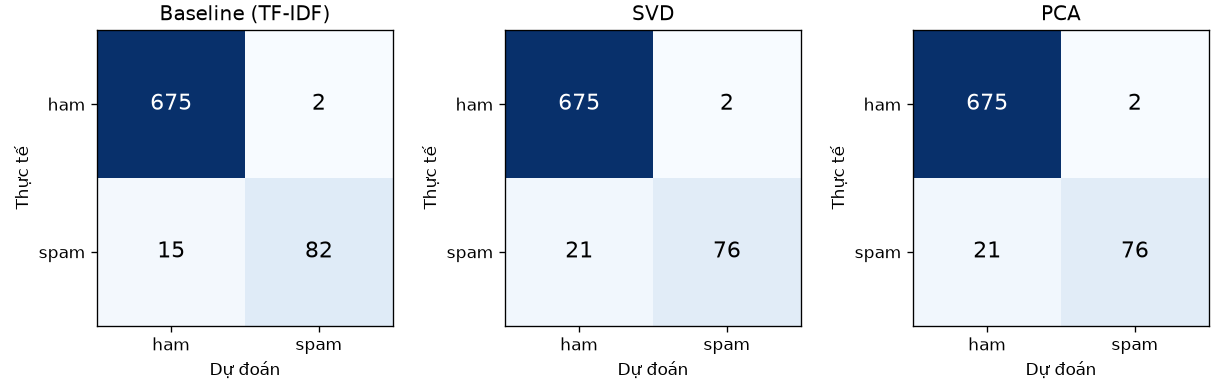

baseline: bắt 82/97 spam, bỏ sót 15; báo nhầm 2/677 ham
svd     : bắt 76/97 spam, bỏ sót 21; báo nhầm 2/677 ham
pca     : bắt 76/97 spam, bỏ sót 21; báo nhầm 2/677 ham


In [15]:
matrices = json.loads((RESULTS / "confusion_matrices.json").read_text(encoding="utf-8"))["matrices"]
plots.plot_confusion_matrices(matrices, FIGURES / "test_confusion.png")
show_figure("test_confusion.png")
for method, ((tn, fp), (fn, tp)) in matrices.items():
    print(f"{method:8s}: bắt {tp}/{tp + fn} spam, bỏ sót {fn}; báo nhầm {fp}/{tn + fp} ham")

**Nhận xét.** Ba mô hình cùng báo nhầm 2/677 tin ham. Khác biệt nằm ở số spam bị bỏ sót: 15/97 tin với baseline, 21/97 tin với SVD và PCA.

Thử hai tin nhắn mới bằng mô hình đã lưu. Các mô hình được load lại từ file, không fit lại:

In [16]:
rows = []
for method in METHODS:
    model = load_pipeline(OUTPUT_ROOT / "models" / method)
    rows += [{"pipeline": method, **predict_message(model, text)} for text in DEMO_MESSAGES]
show_table(pd.DataFrame(rows))

| pipeline | text | prediction | spam_probability |
|---|---|---|---|
| baseline | Can we meet at the library tomorrow? | ham | 0.0148 |
| baseline | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9696 |
| svd | Can we meet at the library tomorrow? | ham | 0.0113 |
| svd | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9855 |
| pca | Can we meet at the library tomorrow? | ham | 0.0123 |
| pca | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9856 |

**Nhận xét.** Cả ba mô hình đều phân loại đúng hai tin. Đây chỉ là minh họa cách dùng mô hình đã lưu; đánh giá chính là bảng test ở trên.

## 9. Kết luận

In [17]:
base = test.set_index("method").loc["baseline", "macro_f1"]
show_table(pd.DataFrame([
    {"Pipeline": row.method, "Số chiều": 1000 if row.method == "baseline" else int(row.k),
     "Macro-F1 test": row.macro_f1, "Chênh lệch so với baseline": row.macro_f1 - base}
    for row in test.itertuples()
]))

| Pipeline | Số chiều | Macro-F1 test | Chênh lệch so với baseline |
|---|---|---|---|
| baseline | 1000 | 0.9468 | 0.0000 |
| svd | 100 | 0.9259 | -0.0209 |
| pca | 100 | 0.9259 | -0.0209 |

- **Từ loss đến score.** Mọi bước học đều làm một loss nhỏ lại rồi được đánh giá bằng một score. SVD/PCA cực tiểu sai số tái tạo $\Vert X - X_k \Vert_F^2$ (score: năng lượng/phương sai giữ lại). Logistic Regression cực tiểu cross-entropy bằng gradient descent (score: macro-F1 trên dữ liệu chưa dùng để học).
- **Kết quả.** Giảm từ 1000 xuống 100 chiều (bớt 90% số cột) làm macro-F1 test giảm từ 0,9468 xuống 0,9259, chủ yếu vì bỏ sót thêm 6 tin spam (21 so với 15).
- **Giả thuyết về nguyên nhân.** SVD/PCA chọn các hướng giữ nhiều năng lượng/phương sai nhất mà không nhìn nhãn. Khi fit trên train (mục 4–5), 100 chiều chỉ giữ 43,1% năng lượng (SVD) và 41,5% phương sai (PCA), nên phần bị bỏ đi có thể vẫn chứa tín hiệu phân biệt spam. Loss tái tạo nhỏ nhất không đồng nghĩa với phân loại tốt nhất. Đồ án chưa có thí nghiệm riêng để kiểm chứng giả thuyết này.
- **SVD và PCA cho kết quả gần như nhau** (cùng confusion matrix trên test). Một lý do có thể là hướng đầu của SVD gần trùng $\mu$ ($\cos = 0{,}989$), còn Logistic Regression đã có hệ số chặn $b$ để xử lý phần trung bình.
- **Giới hạn.** Đồ án chỉ dùng một lần chia dữ liệu, ba giá trị k, vocabulary 1000 từ và SMS tiếng Anh; chênh lệch giữa các mô hình chưa được kiểm định thống kê.

## 10. Tài liệu tham khảo

- T. A. Almeida, J. M. Gómez Hidalgo, A. Yamakami (2011). *Contributions to the Study of SMS Spam Filtering: New Collection and Results*. ACM DocEng. Dữ liệu: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
- C. D. Manning, P. Raghavan, H. Schütze (2008). *Introduction to Information Retrieval*, chương 6 (TF-IDF) và chương 18 (SVD, xấp xỉ hạng thấp).
- L. N. Trefethen, D. Bau (1997). *Numerical Linear Algebra*, SIAM: SVD, QR và lặp trực giao.
- C. Eckart, G. Young (1936). *The approximation of one matrix by another of lower rank*. Psychometrika 1(3).
- C. M. Bishop (2006). *Pattern Recognition and Machine Learning*, mục 4.3 (Logistic Regression) và chương 12 (PCA).